# Caminos en una rejilla

Un robot va de la esquina superior izquierda de una rejilla de $f \times c$ casillas a la inferior derecha moviéndose solo a la derecha o hacia abajo. A cada casilla se llega desde la de arriba o desde la de la izquierda, así que el número de caminos y el camino de suma mínima cumplen

$$N[i][j] = N[i-1][j] + N[i][j-1], \qquad S[i][j] = a_{ij} + \min(S[i-1][j],\ S[i][j-1])$$

(con $N = 0$ en las casillas bloqueadas). Hay $\binom{f + c - 2}{f - 1}$ caminos, pero la tabla cuesta $O(f \cdot c)$.

## 1. Contar caminos

Contar los caminos de una rejilla con la tabla y comprobar que coinciden con el número combinatorio $\binom{f + c - 2}{f - 1}$: un camino es elegir en qué $f - 1$ de los $f + c - 2$ pasos se baja.

In [1]:
import math

def cuenta_caminos(filas, columnas):
    N = [[1] * columnas for _ in range(filas)]
    for i in range(1, filas):
        for j in range(1, columnas):
            N[i][j] = N[i - 1][j] + N[i][j - 1]
    return N[-1][-1]

for f in range(1, 12):
    for c in range(1, 12):
        assert cuenta_caminos(f, c) == math.comb(f + c - 2, f - 1)
print(cuenta_caminos(3, 7), cuenta_caminos(10, 10), cuenta_caminos(30, 30))

28 48620 30067266499541040


## 2. Rejilla con obstáculos

Contar los caminos cuando algunas casillas están bloqueadas (`#`). Comprobarlo contra fuerza bruta: generar todos los caminos eligiendo las posiciones de las bajadas con `itertools.combinations` y descartar los que pisan un obstáculo.

In [2]:
import random
from itertools import combinations

def cuenta_con_obstaculos(rejilla):
    filas, columnas = len(rejilla), len(rejilla[0])
    N = [[0] * columnas for _ in range(filas)]
    for i in range(filas):
        for j in range(columnas):
            if rejilla[i][j] == "#":
                continue
            if i == j == 0:
                N[i][j] = 1
            else:
                N[i][j] = (N[i - 1][j] if i else 0) + (N[i][j - 1] if j else 0)
    return N[-1][-1]

def caminos(filas, columnas):
    pasos = filas + columnas - 2
    for bajadas in combinations(range(pasos), filas - 1):
        i = j = 0
        camino = [(0, 0)]
        for p in range(pasos):
            i, j = (i + 1, j) if p in bajadas else (i, j + 1)
            camino.append((i, j))
        yield camino

def obstaculos_fuerza_bruta(rejilla):
    return sum(all(rejilla[i][j] != "#" for i, j in camino) for camino in caminos(len(rejilla), len(rejilla[0])))

ejemplo = ["....",
           ".#..",
           "...#",
           "#..."]
print(cuenta_con_obstaculos(ejemplo))

random.seed(1)
for _ in range(300):
    f, c = random.randint(1, 6), random.randint(1, 6)
    rejilla = ["".join("#" if random.random() < 0.25 else "." for _ in range(c)) for _ in range(f)]
    assert cuenta_con_obstaculos(rejilla) == obstaculos_fuerza_bruta(rejilla)

3


## 3. Camino de suma mínima

Cada casilla tiene un coste y se busca el camino de suma mínima. Rellenar $S$, reconstruir el camino desde la esquina final eligiendo la casilla anterior más barata y comprobarlo contra fuerza bruta.

In [3]:
def camino_minimo(costes):
    filas, columnas = len(costes), len(costes[0])
    S = [[0] * columnas for _ in range(filas)]
    for i in range(filas):
        for j in range(columnas):
            anteriores = ([S[i - 1][j]] if i else []) + ([S[i][j - 1]] if j else [])
            S[i][j] = costes[i][j] + min(anteriores, default=0)
    camino, i, j = [(filas - 1, columnas - 1)], filas - 1, columnas - 1
    while (i, j) != (0, 0):
        if j == 0 or (i > 0 and S[i - 1][j] <= S[i][j - 1]):
            i -= 1
        else:
            j -= 1
        camino.append((i, j))
    return S[-1][-1], camino[::-1]

costes = [[1, 3, 1, 2],
          [1, 5, 1, 9],
          [4, 2, 1, 1]]
print(camino_minimo(costes))

random.seed(2)
for _ in range(300):
    f, c = random.randint(1, 6), random.randint(1, 6)
    costes = [[random.randint(0, 9) for _ in range(c)] for _ in range(f)]
    suma, camino = camino_minimo(costes)
    assert suma == sum(costes[i][j] for i, j in camino)
    assert suma == min(sum(costes[i][j] for i, j in cam) for cam in caminos(f, c))

(8, [(0, 0), (0, 1), (0, 2), (1, 2), (2, 2), (2, 3)])


## 4. Dibujar el camino mínimo con obstáculos

Generar una rejilla de $25 \times 40$ con costes aleatorios y obstáculos (coste infinito), calcular el camino de suma mínima y dibujarlo con `matplotlib` sobre el mapa de costes.

suma mínima 226 en 64 casillas


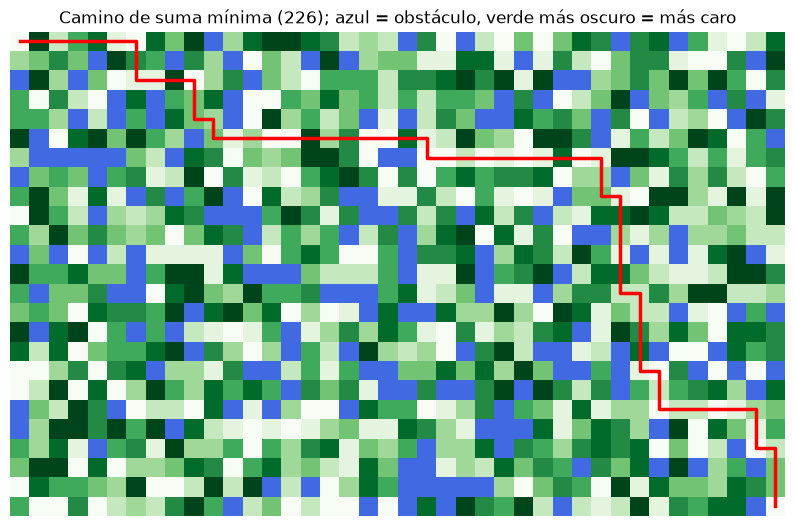

In [4]:
import matplotlib.pyplot as plt
import numpy as np

random.seed(3)
filas, columnas = 25, 40
costes = [[random.randint(1, 9) for _ in range(columnas)] for _ in range(filas)]
for _ in range(180):
    costes[random.randrange(filas)][random.randrange(columnas)] = math.inf
costes[0][0] = costes[-1][-1] = 1

suma, camino = camino_minimo(costes)
assert suma < math.inf
print(f"suma mínima {suma} en {len(camino)} casillas")

mapa = np.array(costes, dtype=float)
fig, eje = plt.subplots(figsize=(10, 6.5))
eje.imshow(np.where(np.isinf(mapa), np.nan, mapa), cmap="Greens")
eje.imshow(np.where(np.isinf(mapa), 1, np.nan), cmap=plt.matplotlib.colors.ListedColormap(["royalblue"]))
eje.plot([j for _, j in camino], [i for i, _ in camino], color="red", linewidth=2.5)
eje.set_title(f"Camino de suma mínima ({suma}); azul = obstáculo, verde más oscuro = más caro")
eje.axis("off")
plt.show()

## 5. Con pasos en diagonal: números de Delannoy

Si también se permite el paso en diagonal (abajo a la derecha), $N[i][j] = N[i-1][j] + N[i][j-1] + N[i-1][j-1]$. Comprobar la tabla contra una recursión que prueba los tres movimientos y contra la fórmula de los números de Delannoy $D(m, n) = \sum_{k} \binom{m}{k} \binom{n}{k} 2^k$, con $m = f - 1$ y $n = c - 1$.

In [5]:
def cuenta_con_diagonal(filas, columnas):
    N = [[1] * columnas for _ in range(filas)]
    for i in range(1, filas):
        for j in range(1, columnas):
            N[i][j] = N[i - 1][j] + N[i][j - 1] + N[i - 1][j - 1]
    return N[-1][-1]

def diagonal_recursiva(i, j):
    if i == 0 or j == 0:
        return 1
    return diagonal_recursiva(i - 1, j) + diagonal_recursiva(i, j - 1) + diagonal_recursiva(i - 1, j - 1)

def delannoy(m, n):
    return sum(math.comb(m, k) * math.comb(n, k) * 2 ** k for k in range(min(m, n) + 1))

for f in range(1, 8):
    for c in range(1, 8):
        assert cuenta_con_diagonal(f, c) == diagonal_recursiva(f - 1, c - 1) == delannoy(f - 1, c - 1)
print([cuenta_con_diagonal(n, n) for n in range(1, 9)])

[1, 3, 13, 63, 321, 1683, 8989, 48639]
